# Employee Engagement and Attrition: Can Survey Scores Flag Who Might Leave?

**Questions**
1. How do employees rate their job, environment, relationships, involvement and work-life balance?
2. Are low survey scores linked to people leaving?
3. Can a simple early-warning system, built from survey answers and a few HR fields, flag employees at risk before they leave?

**Data:** the IBM HR Analytics Employee Attrition dataset: 1,470 employees, each with five 1-to-4 survey ratings, job and pay details, and whether they left the company. It is a **fictional dataset created by IBM data scientists** for teaching and demonstrations, so the findings illustrate the method rather than describe a real company.

**Tools:** Python, pandas, matplotlib, scipy, statsmodels, scikit-learn. The companion interactive dashboard is in the `dashboard/` folder.

## 1. Setup and data

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from pathlib import Path

DEEP, DARK, MID, LIGHT, SOFT, PLUM = "#880E4F", "#D81B60", "#F48FB1", "#F8BBD0", "#E8A0BF", "#AD1457"   # pink palette
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "svg.fonttype": "none"})
Path("images").mkdir(exist_ok=True)

hr = pd.read_csv("data/ibm_hr_attrition.csv")
print(hr.shape, "| missing values:", int(hr.isna().sum().sum()), "| duplicate employees:", int(hr.EmployeeNumber.duplicated().sum()))
constant = [c for c in hr.columns if hr[c].nunique() == 1]
print("columns with a single value (dropped):", constant)
hr = hr.drop(columns=constant)
hr["left"] = (hr.Attrition == "Yes").astype(int)
print(f"employees who left: {hr.left.sum()} of {len(hr)} ({hr.left.mean():.1%})")

(1470, 35) | missing values: 0 | duplicate employees: 0
columns with a single value (dropped): ['EmployeeCount', 'Over18', 'StandardHours']
employees who left: 237 of 1470 (16.1%)


Five columns are survey questions answered on a 1 to 4 scale:

| Column | Scale |
|---|---|
| Job satisfaction, environment satisfaction, relationship satisfaction | 1 Low, 2 Medium, 3 High, 4 Very high |
| Job involvement | 1 Low, 2 Medium, 3 High, 4 Very high |
| Work-life balance | 1 Bad, 2 Good, 3 Better, 4 Best |

I combine the five into an **engagement index**: the average of the five ratings, from 1 to 4.

In [2]:
ITEMS = {"JobSatisfaction": "Job satisfaction", "EnvironmentSatisfaction": "Environment", "RelationshipSatisfaction": "Relationships",
         "JobInvolvement": "Job involvement", "WorkLifeBalance": "Work-life balance"}
hr["engagement"] = hr[list(ITEMS)].mean(axis=1)
print(hr[list(ITEMS) + ["engagement"]].describe().round(2).T[["mean", "std", "min", "50%", "max"]].to_string())

                          mean   std  min  50%  max
JobSatisfaction           2.73  1.10  1.0  3.0  4.0
EnvironmentSatisfaction   2.72  1.09  1.0  3.0  4.0
RelationshipSatisfaction  2.71  1.08  1.0  3.0  4.0
JobInvolvement            2.73  0.71  1.0  3.0  4.0
WorkLifeBalance           2.76  0.71  1.0  3.0  4.0
engagement                2.73  0.43  1.2  2.8  4.0


## 2. How do employees rate each area?

                      1     2     3     4
Job satisfaction   19.7  19.0  30.1  31.2
Environment        19.3  19.5  30.8  30.3
Relationships      18.8  20.6  31.2  29.4
Job involvement     5.6  25.5  59.0   9.8
Work-life balance   5.4  23.4  60.7  10.4


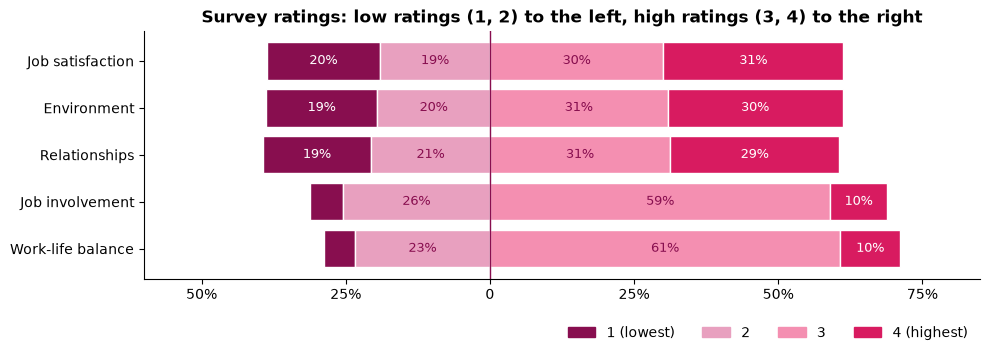

In [3]:
dist = pd.DataFrame({ITEMS[c]: hr[c].value_counts(normalize=True).sort_index() * 100 for c in ITEMS}).T
print(dist.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
colors = {1: DEEP, 2: SOFT, 3: MID, 4: DARK}
rows = dist.index[::-1]
for i, item in enumerate(rows):
    left = -(dist.loc[item, 1] + dist.loc[item, 2])            # low ratings to the left of zero
    for lvl in (1, 2, 3, 4):
        w = dist.loc[item, lvl]
        ax.barh(i, w, left=left, color=colors[lvl], edgecolor="white")
        if w >= 9: ax.text(left + w / 2, i, f"{w:.0f}%", ha="center", va="center", fontsize=9, color="white" if lvl in (1, 4) else DEEP)
        left += w
ax.axvline(0, color=DEEP, lw=1)
ax.set_yticks(range(len(rows)), rows); ax.set_xlim(-60, 85)
ax.set_xticks([-50, -25, 0, 25, 50, 75], ["50%", "25%", "0", "25%", "50%", "75%"])
ax.set_title("Survey ratings: low ratings (1, 2) to the left, high ratings (3, 4) to the right")
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[k]) for k in (1, 2, 3, 4)]
ax.legend(handles, ["1 (lowest)", "2", "3", "4 (highest)"], frameon=False, ncol=4, loc="lower right", bbox_to_anchor=(1, -0.3))
plt.tight_layout(); plt.savefig("images/survey_ratings.svg"); plt.show()

The five questions fall into two groups:

- **Job satisfaction, environment and relationships** are split: about 40% of employees gave a low rating (1 or 2) and about 60% a high one (3 or 4).
- **Job involvement and work-life balance** cluster in the middle. Roughly 60% chose 3, and fewer than 6% chose 1.

The average on every question is close to 2.7 out of 4, and so is the engagement index. That makes averages a poor way to spot problems here. The useful signal is in the employees who chose the lowest rating.

## 3. Are low survey scores linked to leaving?

                   left_if_1  left_if_4  ratio_1_vs_4  chi2_p
item                                                         
Job involvement      33.7349     9.0278        3.7368  0.0000
Job satisfaction     22.8374    11.3290        2.0158  0.0006
Environment          25.3521    13.4529        1.8845  0.0001
Work-life balance    31.2500    17.6471        1.7708  0.0010
Relationships        20.6522    14.8148        1.3940  0.1550


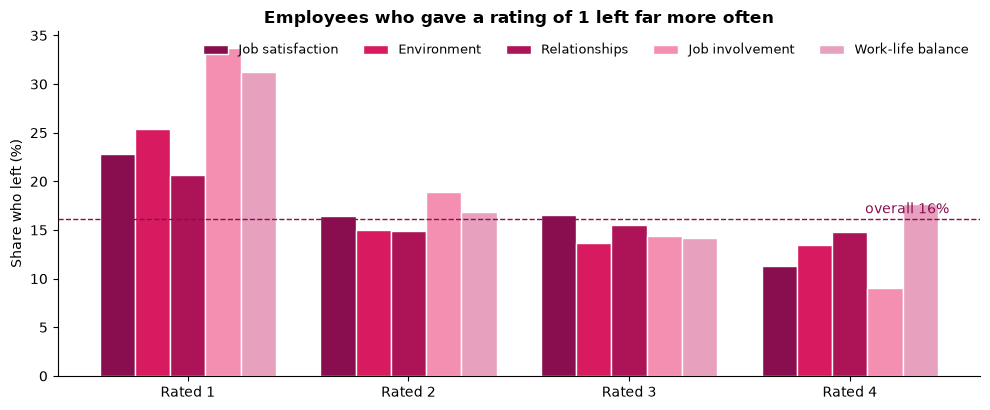

In [4]:
rows = []
for c, label in ITEMS.items():
    tab = pd.crosstab(hr[c], hr.left)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    rates = hr.groupby(c).left.mean() * 100
    rows.append({"item": label, "left_if_1": rates[1], "left_if_4": rates[4], "ratio_1_vs_4": rates[1] / rates[4], "chi2_p": p})
assoc = pd.DataFrame(rows).set_index("item").sort_values("ratio_1_vs_4", ascending=False)
print(assoc.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(4); w = 0.16
for k, (c, label) in enumerate(ITEMS.items()):
    r = hr.groupby(c).left.mean() * 100
    ax.bar(x + (k - 2) * w, r.values, w, label=label, color=[DEEP, DARK, PLUM, MID, SOFT][k], edgecolor="white")
ax.axhline(hr.left.mean() * 100, color=DEEP, ls="--", lw=1); ax.text(3.45, hr.left.mean() * 100 + 0.6, "overall 16%", color=DEEP, ha="right")
ax.set_xticks(x, ["Rated 1", "Rated 2", "Rated 3", "Rated 4"]); ax.set_ylabel("Share who left (%)")
ax.set_title("Employees who gave a rating of 1 left far more often"); ax.legend(frameon=False, ncol=5, fontsize=9, loc="upper right")
plt.tight_layout(); plt.savefig("images/attrition_by_rating.svg"); plt.show()

On four of the five questions, a rating of 1 goes with a much higher chance of leaving, and the chi-square tests show these differences are very unlikely to be chance (p ≤ 0.001):

- **Job involvement:** 34% of those who rated it 1 left, against 9% of those who rated it 4, almost four times as many.
- **Work-life balance:** 31% left at a rating of 1.
- **Environment and job satisfaction:** 25% and 23% left at a rating of 1, about twice the rate at 4.
- **Relationships** shows the same direction but a weaker link (21% vs 15%, p = 0.16), so on its own it is not a reliable signal.

The combined engagement index shows the same pattern: 37% of employees with the lowest engagement (under 2.2) left, against 10% of those at 3.0 or above.

In [5]:
hr["engagement_band"] = pd.cut(hr.engagement, [0, 2.2, 2.6, 3.0, 4.01], labels=["Low (under 2.2)", "2.2 to 2.6", "2.6 to 3.0", "High (3.0+)"], right=False)
band = hr.groupby("engagement_band", observed=True).agg(employees=("left", "size"), left_pct=("left", "mean"))
band["left_pct"] *= 100
print(band.round(1).to_string())
print(f"\nSpearman correlation, engagement index vs leaving: {stats.spearmanr(hr.engagement, hr.left)[0]:.3f}")

                 employees  left_pct
engagement_band                     
Low (under 2.2)        100      37.0
2.2 to 2.6             332      23.8
2.6 to 3.0             509      13.0
High (3.0+)            529      10.4

Spearman correlation, engagement index vs leaving: -0.180


## 4. Departments, overtime and roles

                        employees  left_pct  engagement  overtime_pct
Department                                                           
Human Resources                63     19.05        2.77         26.98
Research & Development        961     13.84        2.73         28.20
Sales                         446     20.63        2.73         28.70

           employees  left_pct
OverTime                     
No             1054      10.4
Yes             416      30.5

work-life balance rated 1 AND overtime: 22 employees, 45% left

                            employees  left_pct  engagement
JobRole                                                   
Sales Representative              83     39.76        2.72
Laboratory Technician            259     23.94        2.70
Human Resources                   52     23.08        2.75
Sales Executive                  326     17.48        2.73
Research Scientist               292     16.10        2.74
Manufacturing Director           145      6.90   

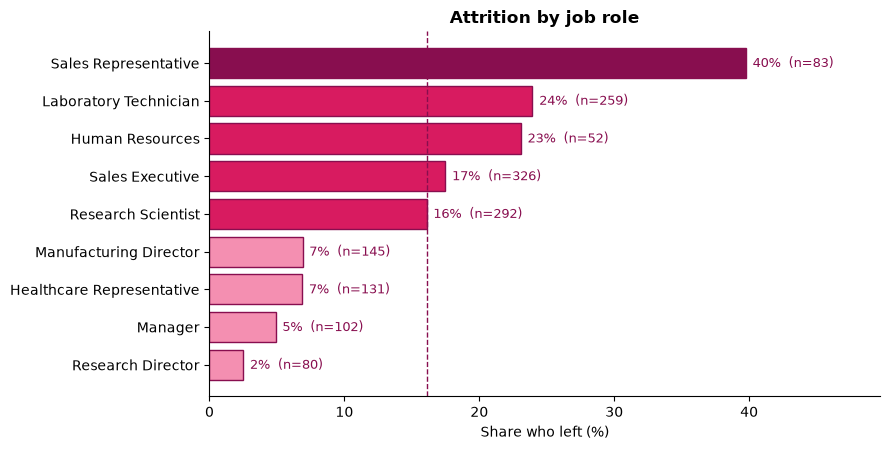

In [6]:
dept = hr.groupby("Department").agg(employees=("left", "size"), left_pct=("left", "mean"), engagement=("engagement", "mean"),
                                     overtime_pct=("OverTime", lambda s: (s == "Yes").mean()))
dept[["left_pct", "overtime_pct"]] *= 100
print(dept.round(2).to_string())

ot = hr.groupby("OverTime").agg(employees=("left", "size"), left_pct=("left", "mean"))
ot["left_pct"] *= 100
print("\n", ot.round(1).to_string())
print(f"\nwork-life balance rated 1 AND overtime: {((hr.WorkLifeBalance == 1) & (hr.OverTime == 'Yes')).sum()} employees, "
      f"{hr[(hr.WorkLifeBalance == 1) & (hr.OverTime == 'Yes')].left.mean():.0%} left")

role = hr.groupby("JobRole").agg(employees=("left", "size"), left_pct=("left", "mean"), engagement=("engagement", "mean")).sort_values("left_pct", ascending=False)
role["left_pct"] *= 100
print("\n", role.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4.6))
r = role.sort_values("left_pct")
ax.barh(r.index, r.left_pct, color=[DEEP if v > 25 else (DARK if v > 15 else MID) for v in r.left_pct], edgecolor=DEEP)
for i, (v, n) in enumerate(zip(r.left_pct, r.employees)): ax.text(v + 0.5, i, f"{v:.0f}%  (n={n})", va="center", fontsize=9, color=DEEP)
ax.axvline(hr.left.mean() * 100, color=DEEP, ls="--", lw=1)
ax.set_xlabel("Share who left (%)"); ax.set_title("Attrition by job role"); ax.set_xlim(0, r.left_pct.max() * 1.25)
plt.tight_layout(); plt.savefig("images/attrition_by_role.svg"); plt.show()

**Overtime is the strongest single factor in the data.** 31% of employees who work overtime left, against 10% of those who don't. Among the 22 employees who work overtime *and* rated work-life balance 1, 45% left.

**Role matters more than department.** Sales representatives (40%), laboratory technicians (24%) and HR staff (23%) left most often, while managers and research directors rarely did (5% and 3%). Average engagement is almost the same in every role (2.70 to 2.77), so the differences between roles come from other things, such as seniority and pay, rather than from survey scores.

## 5. Which factors matter once everything is considered together?

Survey scores, overtime, pay and seniority are related to each other: junior employees earn less and may also rate their jobs lower. A logistic regression estimates each factor's link to leaving while holding the others constant. Results are reported as odds ratios: above 1 means higher odds of leaving.

                          odds_ratio  ci_low  ci_high      p
JobSatisfaction                0.694   0.600    0.804  0.000
EnvironmentSatisfaction        0.694   0.599    0.805  0.000
RelationshipSatisfaction       0.815   0.701    0.947  0.007
JobInvolvement                 0.576   0.462    0.719  0.000
WorkLifeBalance                0.755   0.603    0.945  0.014
overtime                       5.713   4.066    8.028  0.000
log_income                     0.397   0.282    0.559  0.000
YearsAtCompany                 0.992   0.955    1.031  0.681
Age                            0.964   0.943    0.985  0.001
single                         2.724   1.957    3.792  0.000
travel_freq                    2.435   1.671    3.550  0.000
DistanceFromHome               1.038   1.018    1.058  0.000
NumCompaniesWorked             1.170   1.094    1.252  0.000

pseudo R-squared: 0.253, n = 1470


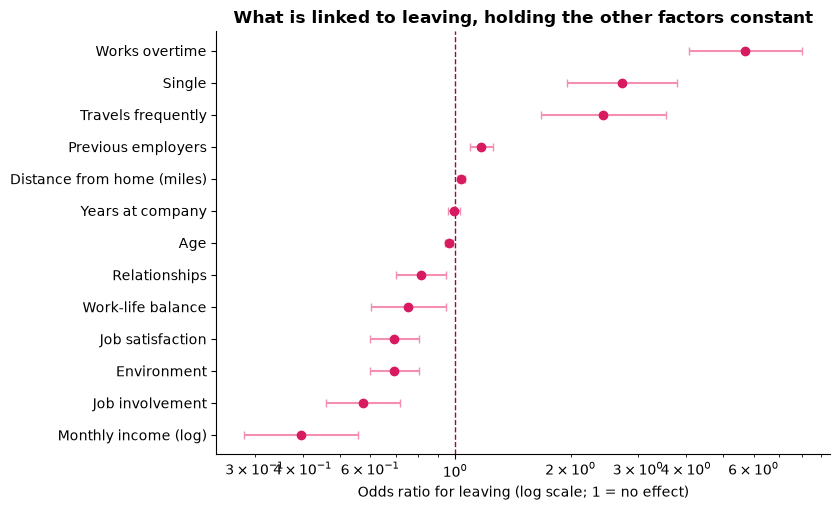

In [7]:
hr["overtime"] = (hr.OverTime == "Yes").astype(int)
hr["log_income"] = np.log(hr.MonthlyIncome)
hr["single"] = (hr.MaritalStatus == "Single").astype(int)
hr["travel_freq"] = (hr.BusinessTravel == "Travel_Frequently").astype(int)
formula = ("left ~ JobSatisfaction + EnvironmentSatisfaction + RelationshipSatisfaction + JobInvolvement + WorkLifeBalance"
           " + overtime + log_income + YearsAtCompany + Age + single + travel_freq + DistanceFromHome + NumCompaniesWorked")
logit = smf.logit(formula, data=hr).fit(disp=0)
ors = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(logit.conf_int()[0]), "ci_high": np.exp(logit.conf_int()[1]), "p": logit.pvalues}).drop("Intercept")
print(ors.round(3).to_string())
print(f"\npseudo R-squared: {logit.prsquared:.3f}, n = {int(logit.nobs)}")

plot = ors.rename(index={**ITEMS, "overtime": "Works overtime", "log_income": "Monthly income (log)", "YearsAtCompany": "Years at company",
                        "single": "Single", "travel_freq": "Travels frequently", "DistanceFromHome": "Distance from home (miles)",
                        "NumCompaniesWorked": "Previous employers", "Age": "Age"}).sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
yy = np.arange(len(plot))
ax.errorbar(plot.odds_ratio, yy, xerr=[plot.odds_ratio - plot.ci_low, plot.ci_high - plot.odds_ratio], fmt="o",
            color=DARK, ecolor=MID, capsize=3, markersize=6)
ax.axvline(1, color=DEEP, lw=1, ls="--"); ax.set_xscale("log")
ax.set_yticks(yy, plot.index); ax.set_xlabel("Odds ratio for leaving (log scale; 1 = no effect)")
ax.set_title("What is linked to leaving, holding the other factors constant")
plt.tight_layout(); plt.savefig("images/odds_ratios.svg"); plt.show()

Holding the other factors constant:

- **Each one-point rise in a survey rating lowers the odds of leaving.** The effect is largest for job involvement (odds ratio 0.58, so 42% lower odds per point) and about 30% lower per point for job and environment satisfaction. All five survey questions are significant once the other factors are included, even relationships.
- **Overtime multiplies the odds of leaving by 5.7**, the largest effect in the model.
- **Other risk factors:** being single (×2.7), travelling frequently (×2.4), each previous employer (×1.17) and each extra mile of commute (×1.04).
- **Higher pay and older age lower the odds.** Years at the company has no effect once age and pay are included.

These are associations, not causes. The data is a snapshot, so it cannot show, for example, whether low satisfaction leads people to leave or whether people who already plan to leave rate their jobs lower.

## 6. An early-warning system

The practical question is whether these signals could help a manager check in with people *before* they leave. I compare two approaches:

- **Simple rules**, which anyone can apply from a spreadsheet: flag an employee who rated any survey question 1, or who works overtime and rated work-life balance 1 or 2.
- **A risk score** from the logistic regression above, flagging the 15% of employees with the highest predicted risk. To keep this honest, every employee's score comes from a model trained on the *other* employees (5-fold cross-validation).

In [8]:
rule = ((hr[list(ITEMS)] == 1).any(axis=1)) | ((hr.overtime == 1) & (hr.WorkLifeBalance <= 2))
X = hr[["JobSatisfaction", "EnvironmentSatisfaction", "RelationshipSatisfaction", "JobInvolvement", "WorkLifeBalance",
        "overtime", "log_income", "YearsAtCompany", "Age", "single", "travel_freq", "DistanceFromHome", "NumCompaniesWorked"]]
cv = StratifiedKFold(5, shuffle=True, random_state=42)
risk = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X, hr.left, cv=cv, method="predict_proba")[:, 1]
hr["risk"] = risk
top = hr.risk >= np.quantile(hr.risk, 0.85)
print(f"cross-validated AUC of the risk score: {roc_auc_score(hr.left, risk):.3f}")

def flag_stats(mask, name):
    return {"approach": name, "flagged": int(mask.sum()), "flagged_pct": mask.mean() * 100,
            "leavers_caught": int(hr.left[mask].sum()), "leavers_caught_pct": hr.left[mask].sum() / hr.left.sum() * 100,
            "flagged_who_left_pct": hr.left[mask].mean() * 100}
warn = pd.DataFrame([flag_stats(rule, "Simple rules"), flag_stats(top, "Risk score, top 15%"),
                     flag_stats(rule & top, "Both")]).set_index("approach")
print(warn.round(1).to_string())
print(f"\nfor comparison, 16.1% of all employees left")

cross-validated AUC of the risk score: 0.813
                     flagged  flagged_pct  leavers_caught  leavers_caught_pct  flagged_who_left_pct
approach                                                                                           
Simple rules             832         56.6             180                75.9                  21.6
Risk score, top 15%      221         15.0             127                53.6                  57.5
Both                     177         12.0             105                44.3                  59.3

for comparison, 16.1% of all employees left


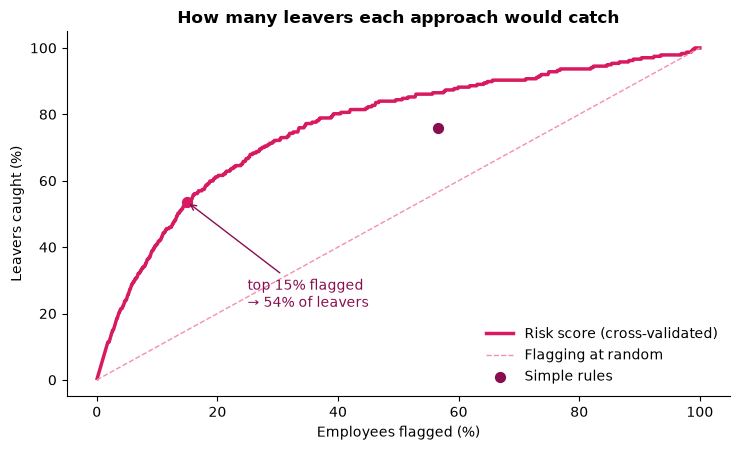

In [9]:
order = np.argsort(-risk)
caught = np.cumsum(hr.left.values[order]) / hr.left.sum() * 100
share = np.arange(1, len(hr) + 1) / len(hr) * 100
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot(share, caught, color=DARK, lw=2.5, label="Risk score (cross-validated)")
ax.plot([0, 100], [0, 100], color=MID, ls="--", lw=1, label="Flagging at random")
r_share, r_caught = rule.mean() * 100, hr.left[rule].sum() / hr.left.sum() * 100
ax.scatter([r_share], [r_caught], color=DEEP, zorder=3, s=50, label="Simple rules")
ax.scatter([15], [caught[int(len(hr) * 0.15) - 1]], color=DARK, zorder=3, s=50)
ax.annotate(f"top 15% flagged\n→ {caught[int(len(hr) * 0.15) - 1]:.0f}% of leavers", (15, caught[int(len(hr) * 0.15) - 1]), xytext=(25, 22),
            arrowprops={"arrowstyle": "->", "color": DEEP}, color=DEEP)
ax.set_xlabel("Employees flagged (%)"); ax.set_ylabel("Leavers caught (%)"); ax.set_title("How many leavers each approach would catch")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("images/early_warning.svg"); plt.show()

The two approaches behave very differently:

| Approach | Employees flagged | Leavers caught | Of those flagged, share who left |
|---|---|---|---|
| Simple rules | 57% | 76% | 22% |
| Risk score, top 15% | 15% | 54% | **58%** |

**The simple rules catch most leavers but flag more than half the company,** which is too many to act on, and only one in five of those flagged actually left. That is barely better than the overall rate of 16%.

**The risk score is far more focused.** Flagging only the top 15% catches more than half of all leavers, and almost three in five of the people it flags did leave. Its cross-validated AUC of 0.81 means it ranks a leaver above a stayer about 81% of the time.

The lesson is that one low survey answer is common and not very informative on its own. Combining the answers with a few HR facts, such as overtime, pay and travel, produces a list short enough for managers to actually follow up on.

## 7. Export for the dashboard

The interactive dashboard reads a small JSON file with one row per employee: department, role, overtime, the five survey ratings, whether they left, and their cross-validated risk score. No names or personal identifiers are included.

In [10]:
cols = ["EmployeeNumber", "Department", "JobRole", "JobLevel", "OverTime", *ITEMS, "left", "risk"]
out = hr[cols].copy()
out["risk"] = out.risk.round(3)
out["rule_flag"] = rule.astype(int)
out["top_risk"] = top.astype(int)
records = out.rename(columns={"EmployeeNumber": "id", "Department": "dept", "JobRole": "role", "JobLevel": "level", "OverTime": "ot",
                              "JobSatisfaction": "job", "EnvironmentSatisfaction": "env", "RelationshipSatisfaction": "rel",
                              "JobInvolvement": "inv", "WorkLifeBalance": "wlb"}).to_dict(orient="records")
Path("dashboard").mkdir(exist_ok=True)
Path("dashboard/data.js").write_text("window.HR_DATA = " + json.dumps(records, separators=(",", ":")) + ";\n")
print(f"wrote dashboard/data.js with {len(records)} employees ({Path('dashboard/data.js').stat().st_size / 1024:.0f} KB)")

wrote dashboard/data.js with 1470 employees (252 KB)


## 8. Conclusions

**Findings**

1. **The lowest survey rating is the warning sign, not the average.** Employees who rated job involvement 1 left at almost four times the rate of those who rated it 4. Average ratings are about 2.7 on every question and hide this.
2. **Overtime is the strongest factor:** 31% of employees on overtime left, against 10% without, and the odds of leaving are 5.7 times higher after accounting for everything else.
3. **Role matters more than department:** sales representatives left at 40%, research directors at 3%.
4. **A combined risk score beats simple rules.** Flagging the top 15% by risk catches 54% of leavers, and 58% of those flagged did leave. Simple rules flag 57% of employees to catch 76%.

**What an HR team could do with this**

- Look at the lowest answers on each survey question, not just averages, and follow up quickly with anyone who rates job involvement or work-life balance 1.
- Review overtime, especially in sales and lab roles, where both overtime and attrition are high.
- Use a short, risk-ranked list for manager check-ins rather than broad rules that flag half the company.

**Limitations**

- **The dataset is fictional,** created by IBM data scientists for teaching. The method carries over to real survey data, but the specific numbers describe no real company.
- **It is a single snapshot.** There are no dates, so the analysis cannot tell whether survey scores came before or after someone decided to leave.
- **Associations, not causes.** For example, overtime may be a sign of understaffed teams rather than a direct cause of leaving.
- **Fairness.** A real risk score should be checked for bias and used only to offer support, never to penalise employees. I left marital status in the model to show its statistical link, but a real system should consider leaving out personal characteristics like this.
- **Small groups.** HR has only 63 employees, so its figures are less certain than those for larger departments.